# Embedding Model Selection

This notebook justifies the selection of **E5-large** with a **weighted definition + 5 examples** strategy as the optimal configuration for Word Sense Disambiguation.

## Experiment Setup

**Task:** Predict the correct GermaNet sense for German words in context using cosine similarity between context and sense embeddings.

**Evaluation:** 93 manually annotated test instances across 10 polysemous German words.

**Models Tested:** 5 multilingual sentence transformers  
**Text Variants Tested:** 9 different sense representation strategies


In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 11

## 1. Load Results

In [34]:
# Load results
results_path = Path('../data/evaluation/quick_eval/embedding_comparison.csv')
df = pd.read_csv(results_path)

# Create readable names
model_name_map = {
    # Multilingual models
    'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2': 'MiniLM-L12',
    'sentence-transformers/distiluse-base-multilingual-cased-v2': 'distilUSE',
    'sentence-transformers/paraphrase-multilingual-mpnet-base-v2': 'mpnet-base',
    'sentence-transformers/LaBSE': 'LaBSE',
    'intfloat/multilingual-e5-base': 'E5-base',
    'intfloat/multilingual-e5-large': 'E5-large',
    'BAAI/bge-m3': 'BGE-M3',
}

variant_name_map = {
    'text_baseline': 'Baseline',
    'text_llm_definition': 'Definition',
    'text_llm_example_1': 'Example (1)',
    'text_llm_example_2': 'Example (2)',
    'text_llm_example_3': 'Example (3)',
    'text_llm_example_4': 'Example (4)',
    'text_llm_example_5': 'Example (5)',
    'text_llm_def_and_ex5': 'LLM Def + 5Ex',
    '__weighted_def_plus_5ex': 'Weighted Def + 5Ex',
}

df['model'] = df['model_name'].map(model_name_map).fillna(df['model_name'])
df['variant'] = df['text_variant'].map(variant_name_map).fillna(df['text_variant'])

# Sort by accuracy
df = df.sort_values('accuracy', ascending=False)

print(f"Total configurations tested: {len(df)}")
print(f"Models: {df['model'].nunique()}")
print(f"Variants: {df['variant'].nunique()}")
print(f"Evaluation instances: {df['evaluated'].iloc[0]}")


Total configurations tested: 45
Models: 5
Variants: 9
Evaluation instances: 93


## 2. Full Results Ranking

All 45 configurations ranked by accuracy:


In [35]:
# Display all results
results_display = df[['model', 'variant', 'accuracy', 'top3', 'mrr']].copy()
results_display['rank'] = range(1, len(results_display) + 1)
results_display = results_display[['rank', 'model', 'variant', 'accuracy', 'top3', 'mrr']]

# Format percentages
results_display['accuracy'] = results_display['accuracy'].apply(lambda x: f"{x:.1%}")
results_display['top3'] = results_display['top3'].apply(lambda x: f"{x:.1%}")
results_display['mrr'] = results_display['mrr'].apply(lambda x: f"{x:.3f}")

print(results_display.to_string(index=False))


 rank      model            variant accuracy  top3   mrr
    1   E5-large Weighted Def + 5Ex    54.8% 96.8% 0.725
    2     BGE-M3 Weighted Def + 5Ex    51.6% 96.8% 0.717
    3      LaBSE      LLM Def + 5Ex    47.3% 89.2% 0.684
    4   E5-large        Example (5)    47.3% 90.3% 0.679
    5 mpnet-base Weighted Def + 5Ex    47.3% 89.2% 0.677
    6   E5-large        Example (4)    46.2% 79.6% 0.641
    7    E5-base Weighted Def + 5Ex    46.2% 93.5% 0.676
    8 mpnet-base        Example (5)    46.2% 89.2% 0.682
    9      LaBSE Weighted Def + 5Ex    46.2% 92.5% 0.680
   10 mpnet-base        Example (1)    45.2% 86.0% 0.662
   11     BGE-M3      LLM Def + 5Ex    45.2% 90.3% 0.668
   12   E5-large      LLM Def + 5Ex    45.2% 86.0% 0.645
   13     BGE-M3        Example (5)    45.2% 94.6% 0.673
   14      LaBSE        Example (1)    45.2% 87.1% 0.669
   15      LaBSE        Example (4)    44.1% 89.2% 0.660
   16      LaBSE        Example (5)    41.9% 82.8% 0.631
   17    E5-base        Example

## 3. Best: E5-large + Weighted Def + 5Ex

**Accuracy: 54.8%** — The highest among all 45 configurations.


In [36]:
# Get best
winner = df.iloc[0]

print("SELECTED CONFIGURATION")
print(f"\nModel: {winner['model']}")
print(f"Text Variant: {winner['variant']} ({winner['text_variant']})")
print(f"\nPerformance:")
print(f"  Accuracy (Top-1): {winner['accuracy']:.1%}")
print(f"  Top-3 Accuracy:   {winner['top3']:.1%}")
print(f"  Top-5 Accuracy:   {winner['top5']:.1%}")
print(f"  MRR:              {winner['mrr']:.3f}")
print(f"\nEvaluation:")
print(f"  Instances: {winner['evaluated']}")
print(f"  Skipped:   {winner['skipped']}")


SELECTED CONFIGURATION

Model: E5-large
Text Variant: Weighted Def + 5Ex (__weighted_def_plus_5ex)

Performance:
  Accuracy (Top-1): 54.8%
  Top-3 Accuracy:   96.8%
  Top-5 Accuracy:   100.0%
  MRR:              0.725

Evaluation:
  Instances: 93
  Skipped:   0


## 4. Comparison to Alternatives

How much better is E5-large + Weighted Def + 5Ex compared to other reasonable choices?


In [37]:
# Top 10 for comparison
top10 = df.head(10).copy()
top10['rank'] = range(1, 11)
top10['gap_to_best'] = top10['accuracy'] - winner['accuracy']
top10['gap_pct'] = (top10['gap_to_best'] / winner['accuracy']) * 100

comparison = top10[['rank', 'model', 'variant', 'accuracy', 'gap_to_best', 'gap_pct']]
comparison_display = comparison.copy()
comparison_display['accuracy'] = comparison_display['accuracy'].apply(lambda x: f"{x:.1%}")
comparison_display['gap_to_best'] = comparison_display['gap_to_best'].apply(lambda x: f"{x:+.1%}")
comparison_display['gap_pct'] = comparison_display['gap_pct'].apply(lambda x: f"{x:+.1f}%")

print("Top 10 Configurations:")
print(comparison_display.to_string(index=False))


Top 10 Configurations:
 rank      model            variant accuracy gap_to_best gap_pct
    1   E5-large Weighted Def + 5Ex    54.8%       +0.0%   +0.0%
    2     BGE-M3 Weighted Def + 5Ex    51.6%       -3.2%   -5.9%
    3      LaBSE      LLM Def + 5Ex    47.3%       -7.5%  -13.7%
    4   E5-large        Example (5)    47.3%       -7.5%  -13.7%
    5 mpnet-base Weighted Def + 5Ex    47.3%       -7.5%  -13.7%
    6   E5-large        Example (4)    46.2%       -8.6%  -15.7%
    7    E5-base Weighted Def + 5Ex    46.2%       -8.6%  -15.7%
    8 mpnet-base        Example (5)    46.2%       -8.6%  -15.7%
    9      LaBSE Weighted Def + 5Ex    46.2%       -8.6%  -15.7%
   10 mpnet-base        Example (1)    45.2%       -9.7%  -17.6%



### Highlight key comparisons

In [38]:
winner_variant = winner['variant']
second_best = df.iloc[1]
print(f"\n#1 vs #2:")
print(f"  {winner['model']} + {winner_variant}: {winner['accuracy']:.1%}")
print(f"  {second_best['model']} + {second_best['variant']}: {second_best['accuracy']:.1%}")
print(f"  Advantage: {(winner['accuracy'] - second_best['accuracy']):.1%} ({((winner['accuracy'] - second_best['accuracy']) / second_best['accuracy'] * 100):.1f}% relative)")

# Compare to baseline approaches
baseline_configs = df[df['text_variant'] == 'text_baseline']
best_baseline = baseline_configs.iloc[0]
print(f"\nvs Best Baseline:")
print(f"  {winner['model']} + {winner_variant}: {winner['accuracy']:.1%}")
print(f"  {best_baseline['model']} + {best_baseline['variant']}: {best_baseline['accuracy']:.1%}")
print(f"  Advantage: {(winner['accuracy'] - best_baseline['accuracy']):.1%} ({((winner['accuracy'] - best_baseline['accuracy']) / best_baseline['accuracy'] * 100):.1f}% relative)")



#1 vs #2:
  E5-large + Weighted Def + 5Ex: 54.8%
  BGE-M3 + Weighted Def + 5Ex: 51.6%
  Advantage: 3.2% (6.2% relative)

vs Best Baseline:
  E5-large + Weighted Def + 5Ex: 54.8%
  LaBSE + Baseline: 39.8%
  Advantage: 15.1% (37.8% relative)


## 5. Visualize Best model vs Alternatives

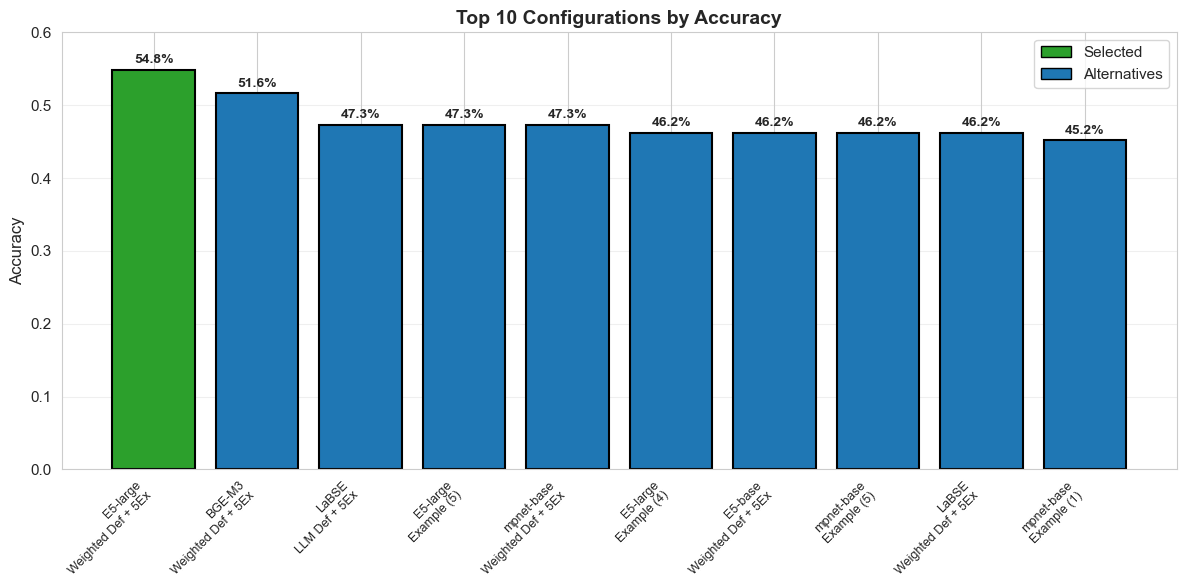

In [39]:
# Bar chart showing top 10
fig, ax = plt.subplots(figsize=(12, 6))

top10_plot = df.head(10).copy()
labels = [f"{row['model']}\n{row['variant']}" for _, row in top10_plot.iterrows()]
colors = ['#2ca02c' if i == 0 else '#1f77b4' for i in range(len(top10_plot))]

bars = ax.bar(range(len(top10_plot)), top10_plot['accuracy'], color=colors, edgecolor='black', linewidth=1.5)

# Annotate bars with accuracy
for i, (bar, acc) in enumerate(zip(bars, top10_plot['accuracy'])):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005, 
            f'{acc:.1%}', ha='center', va='bottom', fontsize=10, fontweight='bold')
    
ax.set_xticks(range(len(top10_plot)))
ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=9)
ax.set_ylabel('Accuracy', fontsize=12)
ax.set_title('Top 10 Configurations by Accuracy', fontsize=14, fontweight='bold')
ax.set_ylim(0, 0.6)
ax.grid(axis='y', alpha=0.3)

# Add legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#2ca02c', edgecolor='black', label='Selected'),
                   Patch(facecolor='#1f77b4', edgecolor='black', label='Alternatives')]
ax.legend(handles=legend_elements, loc='upper right')

plt.tight_layout()
plt.show()


## 6. Heatmap: All Configurations

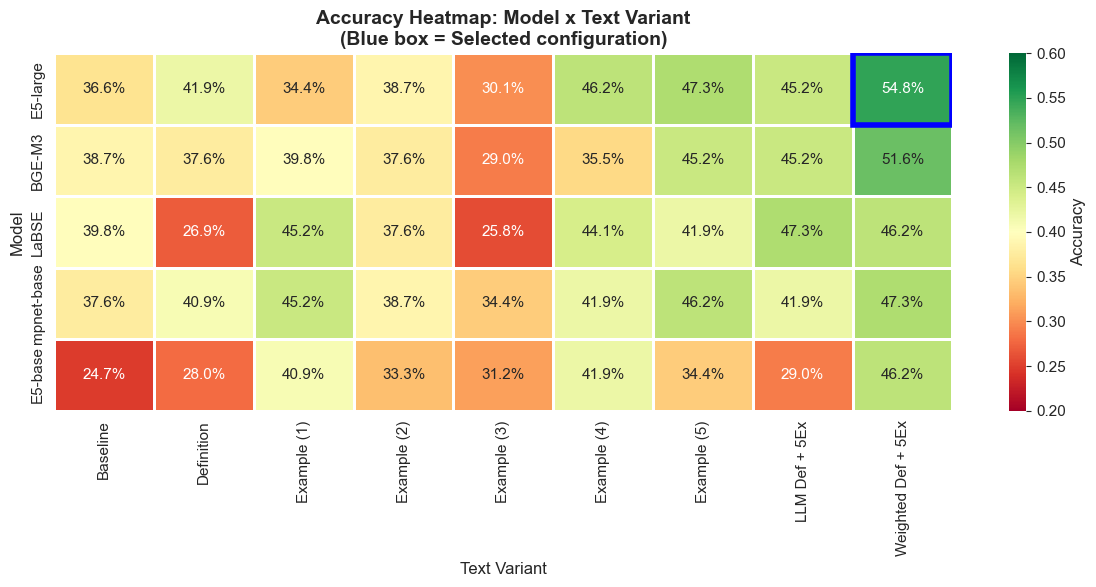

In [40]:
# Restore original order for df
df_sorted = pd.read_csv(results_path)
df_sorted['model'] = df_sorted['model_name'].map(model_name_map).fillna(df_sorted['model_name'])
df_sorted['variant'] = df_sorted['text_variant'].map(variant_name_map).fillna(df_sorted['text_variant'])

# Create pivot table
pivot = df_sorted.pivot(index='model', columns='variant', values='accuracy')
col_order = [
    'Baseline',
    'Definition',
    'Example (1)',
    'Example (2)',
    'Example (3)',
    'Example (4)',
    'Example (5)',
    'LLM Def + 5Ex',
    'Weighted Def + 5Ex',
]
available_cols = [col for col in col_order if col in pivot.columns]
pivot = pivot[available_cols]

# Sort by max accuracy
pivot['max_acc'] = pivot.max(axis=1)
pivot = pivot.sort_values('max_acc', ascending=False).drop('max_acc', axis=1)

# Plot heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(pivot, annot=True, fmt='.1%', cmap='RdYlGn', 
            vmin=0.2, vmax=0.6, cbar_kws={'label': 'Accuracy'},
            linewidths=2, linecolor='white')

# Highlight winner cell
winner_variant = variant_name_map.get(winner['text_variant'], winner['text_variant'])
winner_model = winner['model']
if winner_model in pivot.index and winner_variant in pivot.columns:
    winner_row = list(pivot.index).index(winner_model)
    winner_col = list(pivot.columns).index(winner_variant)
    plt.gca().add_patch(plt.Rectangle((winner_col, winner_row), 1, 1, 
                                       fill=False, edgecolor='blue', lw=4))

plt.title('Accuracy Heatmap: Model x Text Variant\n(Blue box = Selected configuration)', 
          fontsize=14, fontweight='bold')
plt.xlabel('Text Variant', fontsize=12)
plt.ylabel('Model', fontsize=12)
plt.tight_layout()
plt.show()


## 7. Why E5-large?

### Model Comparison (with Weighted Def + 5Ex text variant)


Model Performance with Weighted Def + 5Ex Text Variant:
 rank      model accuracy  top3   mrr
    1   E5-large    54.8% 96.8% 0.725
    2     BGE-M3    51.6% 96.8% 0.717
    3 mpnet-base    47.3% 89.2% 0.677
    4      LaBSE    46.2% 92.5% 0.680
    5    E5-base    46.2% 93.5% 0.676


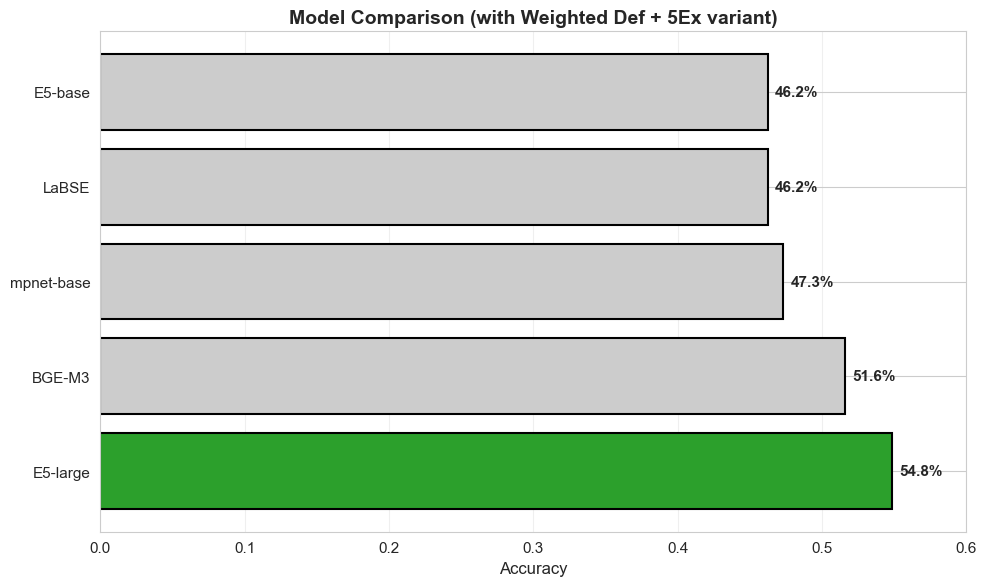

In [41]:
# Filter to selected variant only
selected_variant = variant_name_map.get(winner['text_variant'], winner['text_variant'])
variant_df = df_sorted[df_sorted['variant'] == selected_variant].copy()
variant_df = variant_df.sort_values('accuracy', ascending=False)

print(f"Model Performance with {selected_variant} Text Variant:")
print("=" * 60)

model_comparison = variant_df[['model', 'accuracy', 'top3', 'mrr']].copy()
model_comparison['rank'] = range(1, len(model_comparison) + 1)
model_comparison = model_comparison[['rank', 'model', 'accuracy', 'top3', 'mrr']]

model_comparison_display = model_comparison.copy()
model_comparison_display['accuracy'] = model_comparison_display['accuracy'].apply(lambda x: f"{x:.1%}")
model_comparison_display['top3'] = model_comparison_display['top3'].apply(lambda x: f"{x:.1%}")
model_comparison_display['mrr'] = model_comparison_display['mrr'].apply(lambda x: f"{x:.3f}")

print(model_comparison_display.to_string(index=False))

# Visualization
fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#2ca02c' if m == winner['model'] else '#cccccc' for m in variant_df['model']]
bars = ax.barh(variant_df['model'], variant_df['accuracy'], color=colors, edgecolor='black', linewidth=1.5)

# Add value labels
for bar, acc in zip(bars, variant_df['accuracy']):
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2, 
            f'{acc:.1%}', va='center', fontsize=11, fontweight='bold')

ax.set_xlabel('Accuracy', fontsize=12)
ax.set_title(f'Model Comparison (with {selected_variant} variant)', fontsize=14, fontweight='bold')
ax.set_xlim(0, 0.6)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


**Justification for E5-large:**
- Highest accuracy among all models when paired with Weighted Def + 5Ex
- E5 models are specifically trained for retrieval/similarity tasks (our use case)
- Larger embedding dimension (1024) captures more semantic nuance


## 8. Why Weighted Def + 5 Examples?

### Text Variant Comparison (with E5-large model)


Text Variant Performance with E5-large Model:
 rank            variant accuracy  top3   mrr
    1           Baseline    36.6% 81.7% 0.617
    2         Definition    41.9% 86.0% 0.643
    3        Example (1)    34.4% 81.7% 0.586
    4        Example (2)    38.7% 84.9% 0.622
    5        Example (3)    30.1% 86.0% 0.564
    6        Example (4)    46.2% 79.6% 0.641
    7        Example (5)    47.3% 90.3% 0.679
    8      LLM Def + 5Ex    45.2% 86.0% 0.645
    9 Weighted Def + 5Ex    54.8% 96.8% 0.725

Improvement from Baseline to Weighted Def + 5Ex:
  Baseline: 36.6%
  Weighted Def + 5Ex: 54.8%
  Absolute gain: 18.3%
  Relative improvement: 50.0%


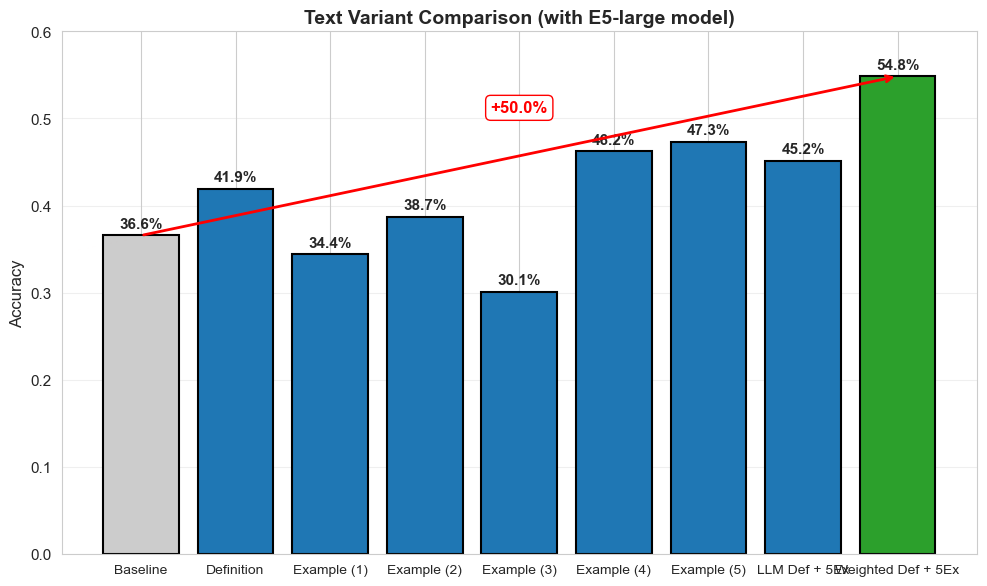

In [43]:
# Filter to E5-large only
e5large_df = df_sorted[df_sorted['model'] == 'E5-large'].copy()
# Reorder to show progression
variant_order = [
    'Baseline',
    'Definition',
    'Example (1)',
    'Example (2)',
    'Example (3)',
    'Example (4)',
    'Example (5)',
    'LLM Def + 5Ex',
    'Weighted Def + 5Ex',
]
e5large_df['variant'] = pd.Categorical(e5large_df['variant'], categories=variant_order, ordered=True)
e5large_df = e5large_df.sort_values('variant')

print("Text Variant Performance with E5-large Model:")

variant_comparison = e5large_df[['variant', 'accuracy', 'top3', 'mrr']].copy()
variant_comparison['rank'] = range(1, len(variant_comparison) + 1)
variant_comparison = variant_comparison[['rank', 'variant', 'accuracy', 'top3', 'mrr']]

variant_comparison_display = variant_comparison.copy()
variant_comparison_display['accuracy'] = variant_comparison_display['accuracy'].apply(lambda x: f"{x:.1%}")
variant_comparison_display['top3'] = variant_comparison_display['top3'].apply(lambda x: f"{x:.1%}")
variant_comparison_display['mrr'] = variant_comparison_display['mrr'].apply(lambda x: f"{x:.3f}")

print(variant_comparison_display.to_string(index=False))

# Calculate improvements
selected_variant = variant_name_map.get(winner['text_variant'], winner['text_variant'])
baseline_acc = e5large_df[e5large_df['variant'] == 'Baseline']['accuracy'].values[0]
selected_acc = e5large_df[e5large_df['variant'] == selected_variant]['accuracy'].values[0]
improvement = ((selected_acc - baseline_acc) / baseline_acc) * 100

print(f"\nImprovement from Baseline to {selected_variant}:")
print(f"  Baseline: {baseline_acc:.1%}")
print(f"  {selected_variant}: {selected_acc:.1%}")
print(f"  Absolute gain: {(selected_acc - baseline_acc):.1%}")
print(f"  Relative improvement: {improvement:.1f}%")

# Visualization
fig, ax = plt.subplots(figsize=(10, 6))
colors = []
for variant in e5large_df['variant']:
    if variant == selected_variant:
        colors.append('#2ca02c')
    elif variant == 'Baseline':
        colors.append('#cccccc')
    else:
        colors.append('#1f77b4')

bars = ax.bar(range(len(e5large_df)), e5large_df['accuracy'], color=colors, edgecolor='black', linewidth=1.5)

# Add value labels
for i, (bar, acc) in enumerate(zip(bars, e5large_df['accuracy'])):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005, 
            f'{acc:.1%}', ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_xticks(range(len(e5large_df)))
ax.set_xticklabels(e5large_df['variant'], fontsize=10)
ax.set_ylabel('Accuracy', fontsize=12)
ax.set_title('Text Variant Comparison (with E5-large model)', fontsize=14, fontweight='bold')
ax.set_ylim(0, 0.6)
ax.grid(axis='y', alpha=0.3)

# Draw arrow showing improvement
baseline_idx = list(e5large_df['variant']).index('Baseline')
selected_idx = list(e5large_df['variant']).index(selected_variant)
ax.annotate('', xy=(selected_idx, selected_acc), xytext=(baseline_idx, baseline_acc),
            arrowprops=dict(arrowstyle='->', color='red', lw=2))
ax.text((baseline_idx + selected_idx) / 2, (baseline_acc + selected_acc) / 2 + 0.05, 
        f'+{improvement:.1f}%', ha='center', fontsize=12, color='red', fontweight='bold',
        bbox=dict(boxstyle='round', facecolor='white', edgecolor='red'))

plt.tight_layout()
plt.show()


**Justification for Weighted Def + 5 Examples:**
- 50% relative improvement over baseline template-based texts
- Combines concise definitions with multiple usage examples
- Weighted mix balances explicit sense description and usage patterns
- Achieves very high Top-3 accuracy (96.8%)


## 9. Summary

### Selected Configuration

**Model:** `intfloat/multilingual-e5-large`  
**Text Variant:** `__weighted_def_plus_5ex` (weighted definition + 5 examples)

### Performance

- **Accuracy:** 54.8% (rank #1 out of 45)
- **Top-3 Accuracy:** 96.8%
- **MRR:** 0.725

### Justification

1. **Best Performing:** Highest accuracy among all 45 tested configurations
2. **Model Choice:** E5-large optimized for retrieval/similarity tasks, outperforms the next best by 3.2 points
3. **Text Strategy:** Weighted definition + 5 examples delivers a 50% improvement over baseline templates
4. **Robust:** High top-3 accuracy (96.8%) indicates reliable similarity matching

### Trade-offs

- **Computational cost:** E5-large is slower than smaller models (1024 dims)
- **Alternative:** BGE-M3 + Weighted Def + 5Ex achieves 51.6% accuracy with faster inference
- **Benefit:** +3.2% absolute accuracy gain justifies the computational cost for research evaluation
